# 03 · Point processes

`.point_process(name, rate)` declares a spike train $n(t) = \sum_k \delta(t - t_k)$ (a counting process) with conditional intensity

$$\Pr\{\text{spike in } [t, t+\mathrm dt)\} = \lambda(t)\,\mathrm dt .$$

The rate is an expression like a drift: parameters, fields, functions, and convolutions `Conv(K, x)` of any field, the spike train itself included. A spike train enters a rate only through a convolution (its instantaneous value is a delta function). The action gains $\tilde n\,n - (e^{\tilde n} - 1)\,\lambda$, so every cumulant of the Poisson noise becomes a vertex.

Covered here:

1. the linear Hawkes process, whose cumulants are known in closed form (an exactness check),
2. a nonlinear (exponential-link) Hawkes process, where loops matter, compared with `SDE.simulate`,
3. the shot-noise $\delta$ component of a spike autocorrelation.

Run time: under a minute.

In [1]:
%matplotlib inline
try:
    preparser(False)   # Sage kernel: plain Python syntax and numbers in the cells below
except NameError:
    pass
import os, sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt
# locate the repository root (the folder holding the 'api' package) from any working directory
_root = os.path.abspath('')
while _root != os.path.dirname(_root) and not os.path.isdir(os.path.join(_root, 'api')):
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
os.chdir(_root)
def ells(r):   # C(tau) per loop order (real parts), a list indexed by the loop order
    return [np.real(np.asarray(r['C_tau_by_ell'][l])) for l in sorted(r['C_tau_by_ell'])]
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
from api.sde import SDE
from api.delay import Kernel
from api import compute_cumulants
from api.pp_simulate import mean_rate, cross_covariance
import daedalus as dd

## 1. Linear Hawkes process: an exact check

$\lambda(t) = \nu + w\,(g * n)(t)$ with $g(t) = e^{-t/\tau}/\tau$ and $0 \le w < 1$. The stationary rate is $\bar\lambda = \nu/(1-w)$ and the smooth part of the spike autocovariance is (Hawkes, 1971)

$$c(\tau) = \bar\lambda\,\frac{w(2-w)}{2\tau_g(1-w)}\,e^{-(1-w)|\tau|/\tau_g}.$$

For a linear intensity the tree diagrams are exact: the loop corrections vanish.

In [3]:
nu, w, tg = 0.5, 0.5, 1.0
lin = (SDE('linear Hawkes')
       .parameter('nu', default=nu, domain='positive').parameter('w', default=w)
       .parameter('tg', default=tg, domain='positive')
       .define_kernel('g', kernel=Kernel.exponential('tg'))
       .point_process('n', 'nu + w*Conv(g, n)'))
lin.show()
tau = np.linspace(-6, 6, 49)
r = compute_cumulants(lin.build(), k=2, max_ell=1, external_fields=[('n', 1), ('n', 1)],
                      tau_grid=tau, parallel=False, verbose=False)
c = ells(r)
lam = nu / (1 - w)
exact = lam * w * (2 - w) / (2 * tg * (1 - w)) * np.exp(-(1 - w) * np.abs(tau) / tg)
print('mean-field rate', float(np.atleast_1d(r['mf_values']['nstar'])[0]), ' exact', lam)
off0 = tau != 0      # tau = 0 is the equal-time (Ito left) limit of the smooth part; reported separately
print('max |tree - exact|, tau != 0:', np.max(np.abs(c[0] - exact)[off0]), '  at tau = 0:', abs(c[0] - exact)[~off0][0])
print('max |one loop| =', np.max(np.abs(c[1])))

# SDE 'linear Hawkes' (ito)
.set_action_text('''
sum(
    nt[i]*n[i] - (exp(nt[i]) - 1)*(nu + w*Conv(g, n[i]))
    for i in pop)
''')
.equation(lhs='n[i]', rhs='nu + w*((1))*(n[i])', population='pop')
mean-field rate 1.0  exact 1.0
max |tree - exact|, tau != 0: 1.1102230246251565e-16   at tau = 0: 0.0
max |one loop| = 0.0


## 2. Nonlinear Hawkes process

An exponential link, $\lambda(t) = a\,\exp\big(b + w\,(g * n)(t)\big)$, is the canonical nonlinear Hawkes process. The mean-field rate solves $\lambda^* = a\,e^{b + w\lambda^*}$; the coupling is kept moderate (the loop gain $w\lambda^* \approx 0.17$): an exponential link with strong self-excitation has a finite chance of running away, which neither the expansion nor a simulation can follow. The loops correct both the rate ($k = 1$) and the autocovariance ($k = 2$).

`SDE.simulate` simulates the same model directly (spikes drawn per time step, the convolution kept as exact exponential filters); `mean_rate` and `cross_covariance` estimate the statistics with batch-means error bars.

In [4]:
hk = (SDE('exponential Hawkes')
      .parameter('a', default=1.0, domain='positive').parameter('b', default=-0.7)
      .parameter('w', default=0.3).parameter('tg', default=1.0, domain='positive')
      .define_kernel('g', kernel=Kernel.exponential('tg'))
      .point_process('n', 'a*exp(b + w*Conv(g, n))'))
model = hk.build()
lags = np.arange(1, 25)                     # lags in bins of 0.25
t0 = time.time()
r1 = compute_cumulants(model, k=1, max_ell=1, external_fields=[('n', 1)], tau_grid=np.array([0.0]),
                       parallel=False, verbose=False)
r2 = compute_cumulants(model, k=2, max_ell=1, external_fields=[('n', 1), ('n', 1)], tau_grid=lags * 0.25,
                       parallel=False, verbose=False)
rate_mf = float(np.atleast_1d(r1['mf_values']['nstar'])[0])
rate_1l = rate_mf + complex(r1['C_tau_by_ell'][1][0]).real
C = ells(r2)
print(f"theory {time.time() - t0:.1f} s: rate mean field {rate_mf:.4f}, with one loop {rate_1l:.4f}")

theory 0.5 s: rate mean field 0.5933, with one loop 0.6051


simulation 2 s: rate 0.6040 +- 0.0030


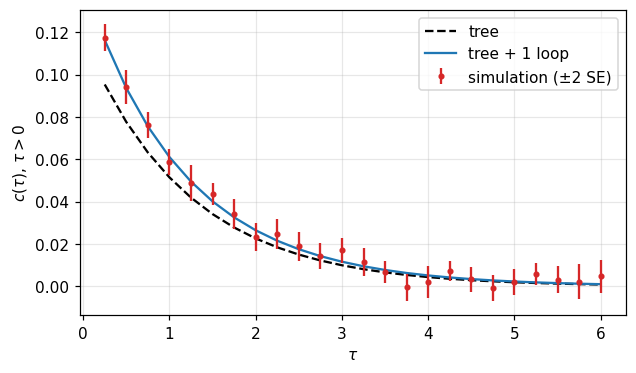

In [5]:
t0 = time.time()
rec = hk.simulate(T=400.0, dt=0.01, n_paths=400, burn_in=40.0, bin=0.25, seed=11)
m, se = mean_rate(rec, 'n', 0)
cov, cse = cross_covariance(rec, ('n', 0), ('n', 0), lags)
print(f"simulation {time.time() - t0:.0f} s: rate {m:.4f} +- {se:.4f}")
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(lags * 0.25, C[0], 'k--', label='tree')
ax.plot(lags * 0.25, C[0] + C[1], label='tree + 1 loop')
ax.errorbar(lags * 0.25, cov, yerr=2 * cse, fmt='o', ms=3, color='C3', label='simulation (±2 SE)')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$c(\tau)$, $\tau > 0$'); ax.legend(); plt.show()

The simulation carries an $O(\mathrm dt)$ bias of order one percent of the rate (one Bernoulli draw per step).

## 3. The $\delta$ component

A spike autocovariance has a singular part $\bar\lambda\,\delta(\tau)$ (each spike is correlated with itself). `compute_cumulants` keeps it out of `C_tau` (the smooth part) and reports it separately; `dd.cumulant(result)` exposes it, and `total_on_grid(mode='bin')` adds it the way a binned estimator sees it.

In [6]:
r0 = compute_cumulants(model, k=2, max_ell=1, external_fields=[('n', 1), ('n', 1)],
                       tau_grid=np.linspace(-2, 2, 17), parallel=False, verbose=False)
cum = dd.cumulant(r0)
for d in cum.deltas:
    print(f"delta at tau = {d.location}: weight {complex(d.weight).real:.5f} (loop order {d.loop_order})")
print('sum of the weights:', sum(complex(d.weight).real for d in cum.deltas), '≈ one-loop rate', round(rate_1l, 5))

delta at tau = 0.0: weight 0.59333 (loop order 0)
delta at tau = 0.0: weight 0.00964 (loop order 1)
delta at tau = 0.0: weight 0.00209 (loop order 1)
sum of the weights: 0.6050554551715168 ≈ one-loop rate 0.60506


## Further

* Several populations: `.population('E', size=N)` and `.point_process('n', 'a*exp(b + sum(w[i,j]*Conv(g[i,j], n[j]) for j in E))', population='E')`.
* A rate may depend on continuous fields (for example a voltage driven by Gaussian noise): `.point_process('n', 'phi(v)')`.
* `Conv(h*g, n)` with two declared kernels is their convolution; `size=` gives each spike a deterministic mark.
* Delayed interactions: tutorial 04 and the delayed-alpha Hawkes example in [`examples/SDE`](../examples/SDE).